# Part C: Text Classification - Preprocessing & Logistic Regression

Goal: classify BBC News articles into 5 topics (business, entertainment, politics, sport, tech).

In [1]:
import os
import re
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

nltk.download("stopwords")
nltk.download("wordnet")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Youssef\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Youssef\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

## 1. Load the data
The file is tab-separated, so we use `sep="\t"`.

In [2]:
df = pd.read_csv("../data/bbc-news-data.csv", sep="\t")
print(df.shape)
df.head()

(2225, 4)


,category,filename,title,content
0,business,001.txt,Ad sales boost Time Warner profit,Quarterly profits at US media giant TimeWarne...
1,business,002.txt,Dollar gains on Greenspan speech,The dollar has hit its highest level against ...
2,business,003.txt,Yukos unit buyer faces loan claim,The owners of embattled Russian oil giant Yuk...
3,business,004.txt,High fuel prices hit BA's profits,British Airways has blamed high fuel prices f...
4,business,005.txt,Pernod takeover talk lifts Domecq,Shares in UK drinks and food firm Allied Dome...


In [3]:
df.info()
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   category  2225 non-null   object
 1   filename  2225 non-null   object
 2   title     2225 non-null   object
 3   content   2225 non-null   object
dtypes: object(4)
memory usage: 69.7+ KB
category    0
filename    0
title       0
content     0
dtype: int64


## 2. Remove duplicates
Duplicate articles could end up in both train and test, which would make the test score look better than it really is.

In [4]:
print("Duplicates:", df.duplicated(subset="content").sum())
df = df.drop_duplicates(subset="content")
print("New shape:", df.shape)

Duplicates: 133
New shape: (2092, 4)


We join the title and the content, because the title is a strong hint of the topic.

In [5]:
df["text"] = df["title"] + " " + df["content"]

## 3. EDA
Check whether the classes are balanced and how long the articles are.

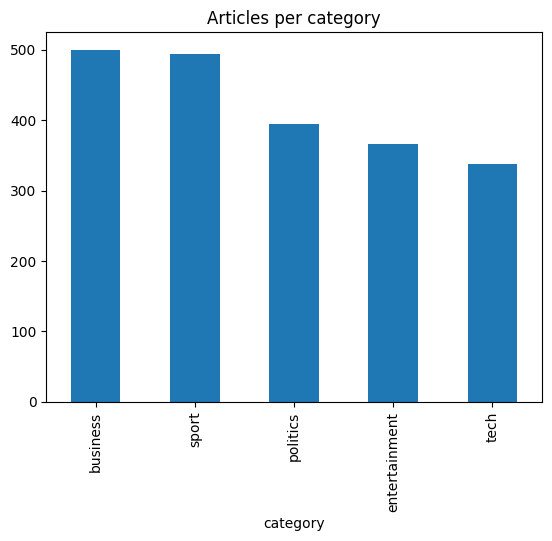

In [6]:
df["category"].value_counts().plot(kind="bar", title="Articles per category")
plt.show()

The classes are roughly balanced (about 390–510 articles each), so accuracy is a fair metric.

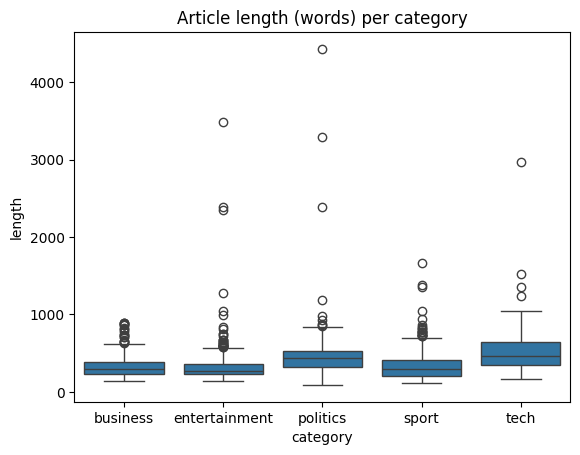

In [7]:
df["length"] = df["text"].apply(lambda t: len(t.split()))
sns.boxplot(data=df, x="category", y="length")
plt.title("Article length (words) per category")
plt.show()

Most articles are 200–500 words long, with a few very long ones. Length is similar across categories, so it can't separate the topics by itself.

## 4. Text cleaning
Steps: lowercase, remove HTML tags, URLs, numbers and punctuation, remove stopwords, then lemmatize ("companies" → "company").

In [8]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)            # HTML tags
    text = re.sub(r"http\S+|www\S+", " ", text)    # URLs
    text = re.sub(r"[^a-z\s]", " ", text)          # numbers and punctuation
    words = text.split()
    words = [lemmatizer.lemmatize(w) for w in words if w not in stop_words and len(w) > 2]
    return " ".join(words)

df["clean_text"] = df["text"].apply(clean_text)

In [9]:
print("Before:", df["text"].iloc[0][:300])
print()
print("After:", df["clean_text"].iloc[0][:300])

Before: Ad sales boost Time Warner profit  Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier.  The firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and highe

After: sale boost time warner profit quarterly profit medium giant timewarner jumped three month december year earlier firm one biggest investor google benefited sale high speed internet connection higher advert sale timewarner said fourth quarter sale rose profit buoyed one gain offset profit dip warner b


Most common words in each category after cleaning:

In [10]:
for category in df["category"].unique():
    words = " ".join(df[df["category"] == category]["clean_text"]).split()
    print(category, ":", pd.Series(words).value_counts().head(10).index.tolist())

business : ['said', 'year', 'company', 'firm', 'market', 'would', 'also', 'sale', 'new', 'bank']
entertainment : ['film', 'said', 'year', 'best', 'award', 'music', 'show', 'also', 'one', 'star']
politics : ['said', 'would', 'government', 'labour', 'party', 'election', 'people', 'minister', 'blair', 'tory']
sport : ['said', 'year', 'game', 'first', 'time', 'player', 'england', 'win', 'back', 'world']
tech : ['said', 'people', 'game', 'technology', 'mobile', 'one', 'phone', 'year', 'also', 'new']


Each category has its own words (film → entertainment, government → politics, player → sport). Words like "said" appear everywhere, but TF-IDF gives them a low weight.

## 5. Split the data (70% train, 15% validation, 15% test)
`stratify` keeps the same class proportions in every part.

In [11]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["category"], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["category"], random_state=42)

print("Train:", len(train_df), " Validation:", len(val_df), " Test:", len(test_df))

Train: 1464  Validation: 314  Test: 314


Save the splits so notebooks 02 and 03 use exactly the same data.

In [12]:
os.makedirs("../data/processed", exist_ok=True)
train_df[["category", "clean_text"]].to_csv("../data/processed/bbc_train.csv", index=False)
val_df[["category", "clean_text"]].to_csv("../data/processed/bbc_val.csv", index=False)
test_df[["category", "clean_text"]].to_csv("../data/processed/bbc_test.csv", index=False)

## 6. TF-IDF
Turn each article into numbers. The vectorizer is fitted on the **training set only**, to avoid data leakage.

In [11]:
vectorizer = TfidfVectorizer(max_features=5000)

X_train = vectorizer.fit_transform(train_df["clean_text"])
X_val = vectorizer.transform(val_df["clean_text"])
X_test = vectorizer.transform(test_df["clean_text"])

y_train = train_df["category"]
y_val = val_df["category"]
y_test = test_df["category"]

print("Vocabulary size:", len(vectorizer.vocabulary_))
print("X_train shape:", X_train.shape)

Vocabulary size: 5000
X_train shape: (1464, 5000)


## 7. Logistic Regression: tuning C on the validation set
Small C = strong regularization (simpler model); large C = weak regularization.

In [12]:
best_C = None
best_f1 = 0

for C in [0.01, 0.1, 1, 10, 100]:
    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_train, y_train)
    f1 = f1_score(y_val, model.predict(X_val), average="macro")
    print("C =", C, " validation F1 =", round(f1, 4))
    if f1 > best_f1:
        best_f1 = f1
        best_C = C

print("Best C:", best_C)

C = 0.01  validation F1 = 0.2891
C = 0.1  validation F1 = 0.9334
C = 1  validation F1 = 0.9806


C = 10  validation F1 = 0.9776
C = 100  validation F1 = 0.9747
Best C: 1


C = 0.01 underfits (F1 ≈ 0.29). The best validation F1 is at **C = 1** (0.98).

In [13]:
log_reg = LogisticRegression(C=best_C, max_iter=1000)
log_reg.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


## 8. Evaluate on the test set

In [14]:
y_pred = log_reg.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred))

Test accuracy: 0.9713
               precision    recall  f1-score   support

     business       0.96      0.97      0.97        75
entertainment       0.95      0.98      0.96        55
     politics       0.97      0.95      0.96        59
        sport       1.00      1.00      1.00        74
         tech       0.98      0.94      0.96        51

     accuracy                           0.97       314
    macro avg       0.97      0.97      0.97       314
 weighted avg       0.97      0.97      0.97       314



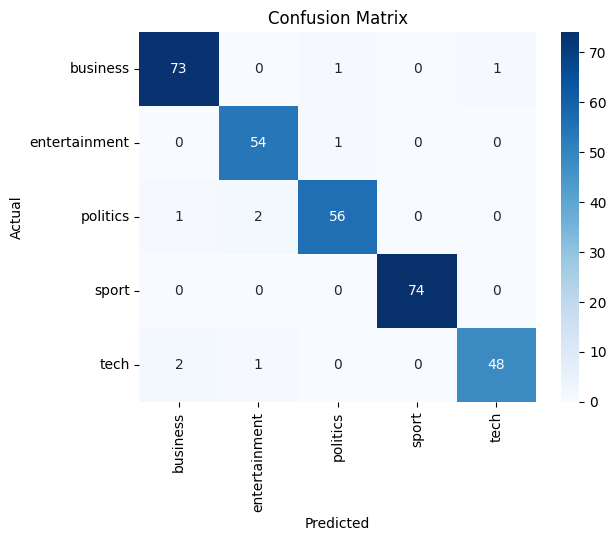

In [17]:
cm = confusion_matrix(y_test, y_pred, labels=log_reg.classes_)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=log_reg.classes_, yticklabels=log_reg.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

Test accuracy is **97%**, with only 9 of 314 articles wrong. Sport is perfect; most mistakes are between politics, business and tech, which can overlap in real news.

## 9. Save the vectorizer and the model

In [18]:
os.makedirs("../models", exist_ok=True)
joblib.dump(vectorizer, "../models/tfidf_vectorizer.joblib")
joblib.dump(log_reg, "../models/text_logistic_model.joblib")
print("Saved")

Saved


**Note for the team:** notebooks 02/03 should load `data/processed/*.csv` and the saved vectorizer (use `transform`, not `fit`). The GUI must apply the same `clean_text` to new text before predicting.